In [1]:
SID4 = 5330
SEED = SID4
print(f"SID4={SID4} SEED={SEED}")

SID4=5330 SEED=5330


# Assignment 8: Mini Diffusion Model (DDPM to DDIM) on MNIST

Configuration from the assignment: T = 100 diffusion steps, β_t linear from 0.0001 to 0.02, batch size 128, 50 epochs.
Pixels are scaled to [-1, 1]. Timesteps are indexed t = 1..T, and t = 0 is the clean image.

In [2]:
import math
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms as T
from torchvision.utils import make_grid

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = "mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

tf = T.Compose([T.ToTensor(), T.Normalize([0.5], [0.5])])
train = datasets.MNIST("../data", train=True, download=True, transform=tf)
test = datasets.MNIST("../data", train=False, download=True, transform=tf)
loader = torch.utils.data.DataLoader(train, batch_size=128, shuffle=True, drop_last=True)
print(len(train), "training images")


def show(x, nrow=8, title=None, ax=None):
    grid = make_grid(x.detach().cpu().clamp(-1, 1) * 0.5 + 0.5, nrow=nrow, padding=2, pad_value=1)
    ax = ax or plt.gca()
    ax.imshow(grid.permute(1, 2, 0)[..., 0], cmap="gray")
    ax.axis("off")
    if title:
        ax.set_title(title)

device: mps
60000 training images


## (a) Forward Diffusion

Noise schedule, with index 0 reserved for t = 0 so that ᾱ_0 = 1:

* β_t linear from 0.0001 to 0.02 for t = 1..100
* α_t = 1 − β_t, ᾱ_t = ∏_{s ≤ t} α_s

Closed-form forward process: x_t = √ᾱ_t · x_0 + √(1 − ᾱ_t) · ε, with ε ~ N(0, I).

In [3]:
T_STEPS = 100
betas = torch.cat([torch.zeros(1), torch.linspace(1e-4, 0.02, T_STEPS)])
alphas = 1 - betas
alpha_bar = torch.cumprod(alphas, 0)
betas, alphas, alpha_bar = betas.to(device), alphas.to(device), alpha_bar.to(device)


def q_sample(x0, t, eps=None):
    """x_t = sqrt(alpha_bar_t) x0 + sqrt(1 - alpha_bar_t) eps, with t a LongTensor of shape [B]."""
    if eps is None:
        eps = torch.randn_like(x0)
    ab = alpha_bar[t].view(-1, 1, 1, 1)
    return ab.sqrt() * x0 + (1 - ab).sqrt() * eps


print(f"alpha_bar_T = {alpha_bar[T_STEPS].item():.4f}")
print(f"signal coefficient sqrt(alpha_bar_T) = {alpha_bar[T_STEPS].sqrt().item():.4f}")
print(f"noise coefficient sqrt(1 - alpha_bar_T) = {(1 - alpha_bar[T_STEPS]).sqrt().item():.4f}")

alpha_bar_T = 0.3636
signal coefficient sqrt(alpha_bar_T) = 0.6030
noise coefficient sqrt(1 - alpha_bar_T) = 0.7978


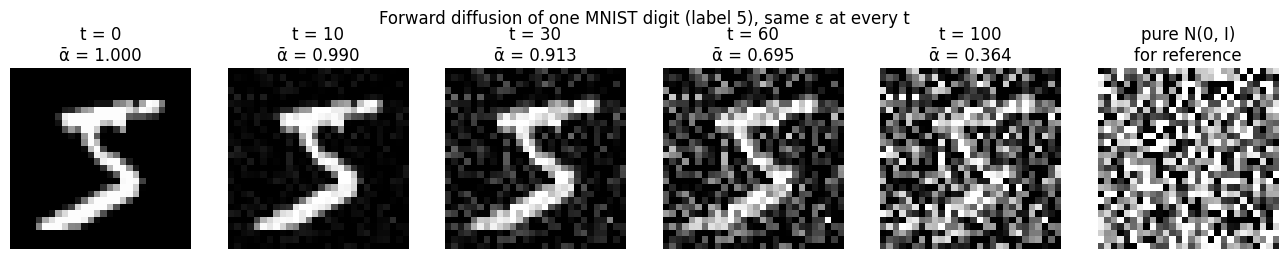

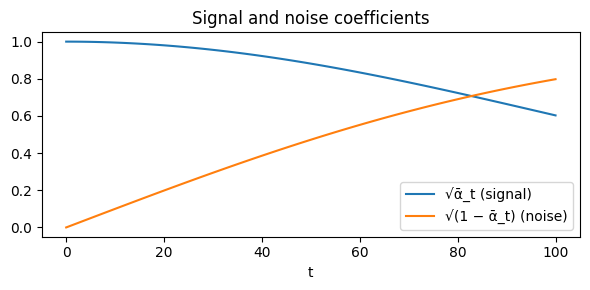

In [4]:
x0 = train[0][0].unsqueeze(0).to(device)
ts = [0, 10, 30, 60, 100]
eps_vis = torch.randn_like(x0)
fig, axes = plt.subplots(1, len(ts) + 1, figsize=(2.2 * (len(ts) + 1), 2.6))
for ax, t in zip(axes, ts):
    xt = q_sample(x0, torch.tensor([t], device=device), eps_vis)
    ax.imshow(xt[0, 0].cpu() * 0.5 + 0.5, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"t = {t}\nᾱ = {alpha_bar[t].item():.3f}")
    ax.axis("off")
axes[-1].imshow(torch.randn(28, 28) * 0.5 + 0.5, cmap="gray", vmin=0, vmax=1)
axes[-1].set_title("pure N(0, I)\nfor reference")
axes[-1].axis("off")
plt.suptitle(f"Forward diffusion of one MNIST digit (label {train[0][1]}), same ε at every t")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 3))
t_axis = np.arange(T_STEPS + 1)
ax.plot(t_axis, alpha_bar.sqrt().cpu(), label="√ᾱ_t (signal)")
ax.plot(t_axis, (1 - alpha_bar).sqrt().cpu(), label="√(1 − ᾱ_t) (noise)")
ax.set_xlabel("t")
ax.legend()
ax.set_title("Signal and noise coefficients")
plt.tight_layout()
plt.show()

The digit fades as t grows. With only 100 steps and β ending at 0.02, though, ᾱ_100 ≈ 0.36, so x_100 still keeps
√ᾱ_100 ≈ 0.60 of the original image. The digit is still faintly visible at t = 100. In the original DDPM setup
(T = 1000), ᾱ_T ≈ 4·10⁻⁵ and x_T is pure noise. This mismatch affects sampling, because sampling starts from pure
N(0, I) even though the model never saw pure noise during training. It is discussed at the end.

## (b) Train a Mini DDPM

**Network ε_θ(x_t, t).** A small U-Net style CNN:

* well over the required 4 convolutional layers (the exact count is printed below): an input conv, two 3×3 convs per residual block, 2 strided down convs, 2 transposed up convs and an output conv
* GroupNorm + SiLU nonlinearity (a smooth ReLU variant)
* **Timestep conditioning:** t is mapped to a 128-d sinusoidal embedding, passed through an MLP, then projected and added
  to the feature maps inside every residual block
* Resolutions 28 → 14 → 7 → 14 → 28 with skip connections, and the output conv returns 1 × 28 × 28, the same shape as the input

**Training.** Sample x_0 from the data, t ~ Uniform{1..100}, ε ~ N(0, I), form x_t with `q_sample`, and minimize
L = MSE(ε, ε_θ(x_t, t)). Adam with lr 2e-4, batch size 128, 50 epochs. An exponential moving average (EMA, decay 0.999)
of the weights is kept and used for sampling, as in the DDPM paper.

In [5]:
def timestep_embedding(t, dim):
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
    args = t.float()[:, None] * freqs[None]
    return torch.cat([args.sin(), args.cos()], dim=1)


class ResBlock(nn.Module):
    def __init__(self, c_in, c_out, t_dim):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, c_in)
        self.conv1 = nn.Conv2d(c_in, c_out, 3, padding=1)
        self.t_proj = nn.Linear(t_dim, c_out)
        self.norm2 = nn.GroupNorm(8, c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, padding=1)
        self.skip = nn.Conv2d(c_in, c_out, 1) if c_in != c_out else nn.Identity()

    def forward(self, x, temb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.t_proj(temb)[:, :, None, None]
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)


class UNet(nn.Module):
    def __init__(self, ch=32, t_dim=128):
        super().__init__()
        self.t_dim = t_dim
        self.t_mlp = nn.Sequential(nn.Linear(t_dim, t_dim * 2), nn.SiLU(), nn.Linear(t_dim * 2, t_dim))
        self.inc = nn.Conv2d(1, ch, 3, padding=1)
        self.down1 = ResBlock(ch, ch, t_dim)                       # 28x28
        self.pool1 = nn.Conv2d(ch, ch * 2, 4, stride=2, padding=1)  # -> 14x14
        self.down2 = ResBlock(ch * 2, ch * 2, t_dim)
        self.pool2 = nn.Conv2d(ch * 2, ch * 2, 4, stride=2, padding=1)  # -> 7x7
        self.mid = ResBlock(ch * 2, ch * 2, t_dim)
        self.up2 = nn.ConvTranspose2d(ch * 2, ch * 2, 4, stride=2, padding=1)  # -> 14x14
        self.dec2 = ResBlock(ch * 4, ch * 2, t_dim)
        self.up1 = nn.ConvTranspose2d(ch * 2, ch, 4, stride=2, padding=1)  # -> 28x28
        self.dec1 = ResBlock(ch * 2, ch, t_dim)
        self.out = nn.Sequential(nn.GroupNorm(8, ch), nn.SiLU(), nn.Conv2d(ch, 1, 3, padding=1))

    def forward(self, x, t):
        temb = self.t_mlp(timestep_embedding(t, self.t_dim))
        h0 = self.down1(self.inc(x), temb)
        h1 = self.down2(self.pool1(h0), temb)
        h = self.mid(self.pool2(h1), temb)
        h = self.dec2(torch.cat([self.up2(h), h1], 1), temb)
        h = self.dec1(torch.cat([self.up1(h), h0], 1), temb)
        return self.out(h)


model = UNet().to(device)
n_conv = sum(isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)) for m in model.modules())
n_params = sum(p.numel() for p in model.parameters())
with torch.no_grad():
    out_shape = model(torch.zeros(2, 1, 28, 28, device=device), torch.tensor([1, 100], device=device)).shape
print(f"conv layers: {n_conv}, parameters: {n_params / 1e6:.2f}M, output shape for [2, 1, 28, 28] input: {list(out_shape)}")

conv layers: 18, parameters: 0.61M, output shape for [2, 1, 28, 28] input: [2, 1, 28, 28]


In [6]:
EPOCHS = 50
EMA_DECAY = 0.999


def train_ddpm(model, epochs):
    """Train with L = MSE(eps, eps_theta(x_t, t)) under the current schedule. Returns the EMA model and the losses."""
    opt = torch.optim.Adam(model.parameters(), lr=2e-4)
    ema = UNet().to(device)
    ema.load_state_dict(model.state_dict())
    ema.requires_grad_(False)
    step_losses, epoch_losses = [], []
    t_start = time.time()
    for epoch in range(epochs):
        model.train()
        running = 0.0
        for x0, _ in loader:
            x0 = x0.to(device)
            t = torch.randint(1, T_STEPS + 1, (x0.size(0),), device=device)
            eps = torch.randn_like(x0)
            loss = F.mse_loss(model(q_sample(x0, t, eps), t), eps)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            with torch.no_grad():
                for pe, pm in zip(ema.parameters(), model.parameters()):
                    pe.lerp_(pm, 1 - EMA_DECAY)
            step_losses.append(loss.item())
            running += loss.item()
        epoch_losses.append(running / len(loader))
        if epoch == 0 or (epoch + 1) % 5 == 0:
            print(f"epoch {epoch + 1:3d}  loss {epoch_losses[-1]:.4f}  elapsed {time.time() - t_start:.0f}s")
    ema.eval()
    return ema, step_losses, epoch_losses


ema, step_losses, epoch_losses = train_ddpm(model, EPOCHS)
torch.save(ema.state_dict(), "ddpm_mnist_ema.pt")

epoch   1  loss 0.1591  elapsed 56s


epoch   5  loss 0.0675  elapsed 298s


epoch  10  loss 0.0608  elapsed 621s


epoch  15  loss 0.0585  elapsed 958s


epoch  20  loss 0.0569  elapsed 1317s


epoch  25  loss 0.0562  elapsed 1683s


epoch  30  loss 0.0554  elapsed 2031s


epoch  35  loss 0.0549  elapsed 2379s


epoch  40  loss 0.0544  elapsed 2747s


epoch  45  loss 0.0545  elapsed 3077s


epoch  50  loss 0.0539  elapsed 3400s


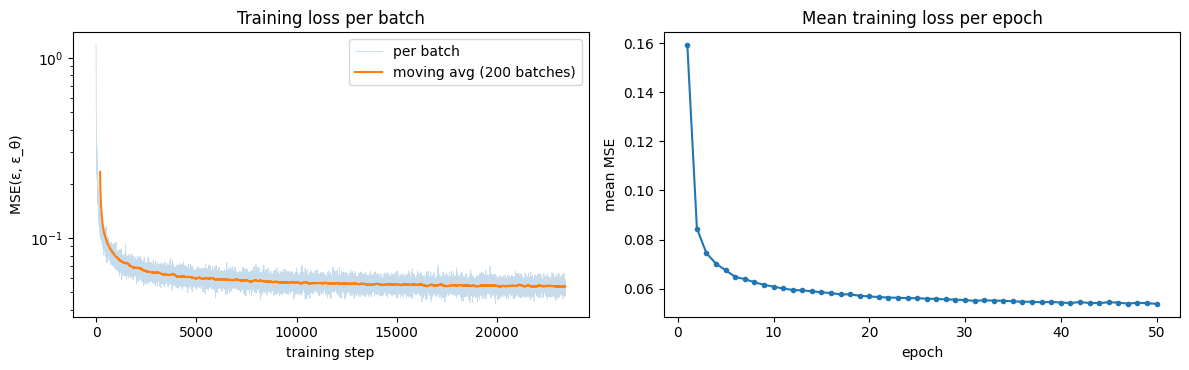

first epoch 0.1591, last epoch 0.0539


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(step_losses, alpha=0.25, lw=0.6, label="per batch")
k = 200
smooth = np.convolve(step_losses, np.ones(k) / k, mode="valid")
axes[0].plot(np.arange(k - 1, len(step_losses)), smooth, label=f"moving avg ({k} batches)")
axes[0].set_yscale("log")
axes[0].set_xlabel("training step")
axes[0].set_ylabel("MSE(ε, ε_θ)")
axes[0].set_title("Training loss per batch")
axes[0].legend()
axes[1].plot(range(1, EPOCHS + 1), epoch_losses, marker="o", ms=3)
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("mean MSE")
axes[1].set_title("Mean training loss per epoch")
plt.tight_layout()
plt.show()
print(f"first epoch {epoch_losses[0]:.4f}, last epoch {epoch_losses[-1]:.4f}")

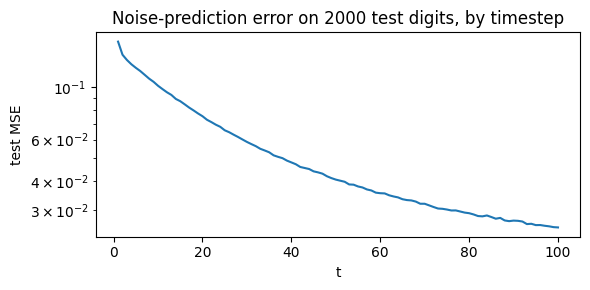

test MSE averaged over t: 0.0525  (t=1: 0.1566, t=100: 0.0254)


In [8]:
# Held-out loss by timestep, using the EMA model on the test set
ema.eval()
test_x = torch.stack([test[i][0] for i in range(2000)]).to(device)
per_t = []
g = torch.Generator(device="cpu").manual_seed(SEED)
with torch.no_grad():
    for t in range(1, T_STEPS + 1):
        tt = torch.full((len(test_x),), t, device=device)
        e = torch.randn(test_x.shape, generator=g).to(device)
        per_t.append(F.mse_loss(ema(q_sample(test_x, tt, e), tt), e).item())
plt.figure(figsize=(6, 3))
plt.plot(range(1, T_STEPS + 1), per_t)
plt.xlabel("t")
plt.ylabel("test MSE")
plt.yscale("log")
plt.title("Noise-prediction error on 2000 test digits, by timestep")
plt.tight_layout()
plt.show()
print(f"test MSE averaged over t: {np.mean(per_t):.4f}  (t=1: {per_t[0]:.4f}, t=100: {per_t[-1]:.4f})")

The loss drops quickly in the first epoch and then decreases slowly. It does not go to zero, because predicting ε is
inherently hard at small t: when x_t is almost clean, the tiny amount of noise is hard to separate from the image.
The per-timestep test curve shows this. The error is largest at small t and smallest at large t, where x_t is mostly noise.

## (c) DDPM Sampling

Start from x_T ~ N(0, I) and step t = T, T−1, …, 1:

1. Predict ε̂ = ε_θ(x_t, t).
2. Estimate the clean image x̂_0 = (x_t − √(1 − ᾱ_t) ε̂) / √ᾱ_t, clipped to [−1, 1].
3. Take the mean of the Gaussian posterior q(x_{t−1} | x_t, x̂_0):
   μ̃ = [√ᾱ_{t−1} β_t / (1 − ᾱ_t)] x̂_0 + [√α_t (1 − ᾱ_{t−1}) / (1 − ᾱ_t)] x_t.
   Without clipping, this is the same as the paper's μ = (x_t − β_t / √(1 − ᾱ_t) · ε̂) / √α_t.
4. x_{t−1} = μ̃ + σ_t z, with z ~ N(0, I) and σ_t² = β̃_t = β_t (1 − ᾱ_{t−1}) / (1 − ᾱ_t). No noise is added at the last step.

Clipping x̂_0 matches the official DDPM implementation (`clip_denoised=True`). It keeps the pixel range valid.

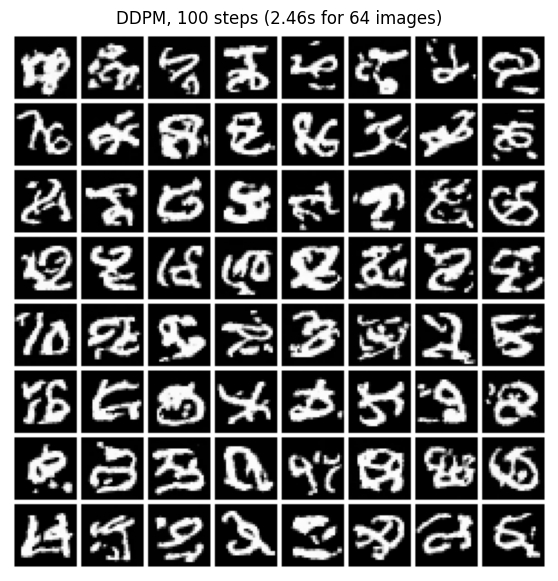

In [9]:
@torch.no_grad()
def ddpm_sample(net, xT, return_traj=False):
    x = xT
    traj = [x]
    for t in range(T_STEPS, 0, -1):
        tt = torch.full((x.size(0),), t, device=device)
        eps = net(x, tt)
        ab_t, ab_prev = alpha_bar[t], alpha_bar[t - 1]
        x0_hat = ((x - (1 - ab_t).sqrt() * eps) / ab_t.sqrt()).clamp(-1, 1)
        mean = (ab_prev.sqrt() * betas[t] / (1 - ab_t)) * x0_hat + (alphas[t].sqrt() * (1 - ab_prev) / (1 - ab_t)) * x
        if t > 1:
            var = betas[t] * (1 - ab_prev) / (1 - ab_t)
            x = mean + var.sqrt() * torch.randn_like(x)
        else:
            x = mean
        traj.append(x)
    return (x, traj) if return_traj else x


N_SAMPLES = 64
g = torch.Generator(device="cpu").manual_seed(SEED)
xT = torch.randn(N_SAMPLES, 1, 28, 28, generator=g).to(device)

torch.manual_seed(SEED)
t0 = time.time()
ddpm_imgs, ddpm_traj = ddpm_sample(ema, xT, return_traj=True)
ddpm_time = time.time() - t0

plt.figure(figsize=(7, 7))
show(ddpm_imgs, title=f"DDPM, 100 steps ({ddpm_time:.2f}s for {N_SAMPLES} images)")
plt.show()

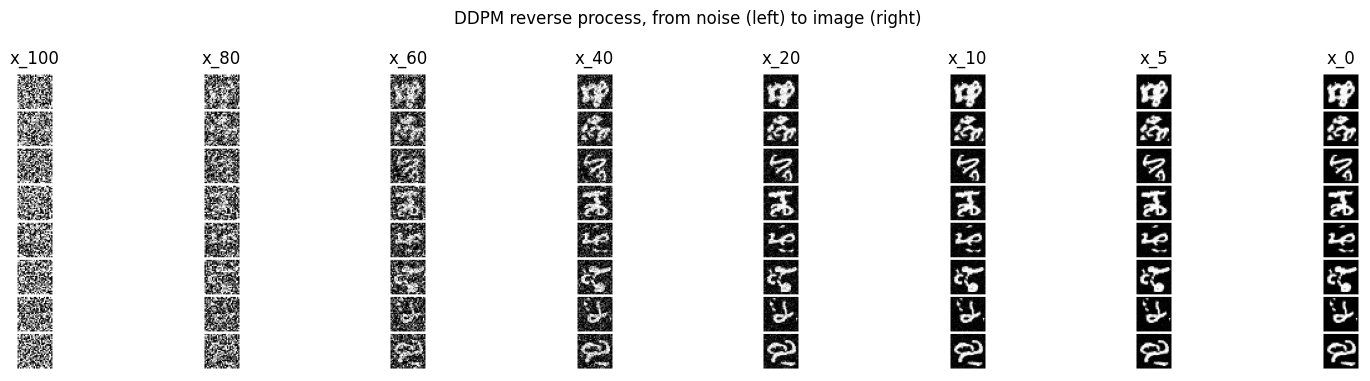

In [10]:
# Reverse trajectory for the first 8 samples
idx = [100, 80, 60, 40, 20, 10, 5, 0]
fig, axes = plt.subplots(1, len(idx), figsize=(2 * len(idx), 2.4 * 1.6))
for ax, t in zip(axes, idx):
    show(ddpm_traj[T_STEPS - t][:8], nrow=1, ax=ax)
    ax.set_title(f"x_{t}")
plt.suptitle("DDPM reverse process, from noise (left) to image (right)")
plt.tight_layout()
plt.show()

## (d) DDIM Sampling

DDIM (Song et al., 2021) uses the same trained ε_θ, with no retraining. It defines a non-Markovian reverse process
that can jump along any increasing subsequence τ_1 < … < τ_S of timesteps. For a step from t to the previous
timestep s in the subsequence:

x̂_0 = (x_t − √(1 − ᾱ_t) ε̂) / √ᾱ_t

x_s = √ᾱ_s · x̂_0 + √(1 − ᾱ_s − σ²) · ε̂ + σ z,  σ = η √[(1 − ᾱ_s) / (1 − ᾱ_t)] · √(1 − ᾱ_t / ᾱ_s)

We use η = 0, so σ = 0 and the sampler is **deterministic**. It reuses the predicted noise ε̂ to move x̂_0 to the
noise level of step s. The S timesteps are evenly spaced, for example 100, 98, …, 2 for S = 50 and 100, 95, …, 5 for
S = 20, and the last step goes to s = 0 (ᾱ_0 = 1). With η = 1 and S = T the update reduces to DDPM. We also run that
case as a check.

After clipping, ε̂ is recomputed from the clipped x̂_0 so that both stay consistent.

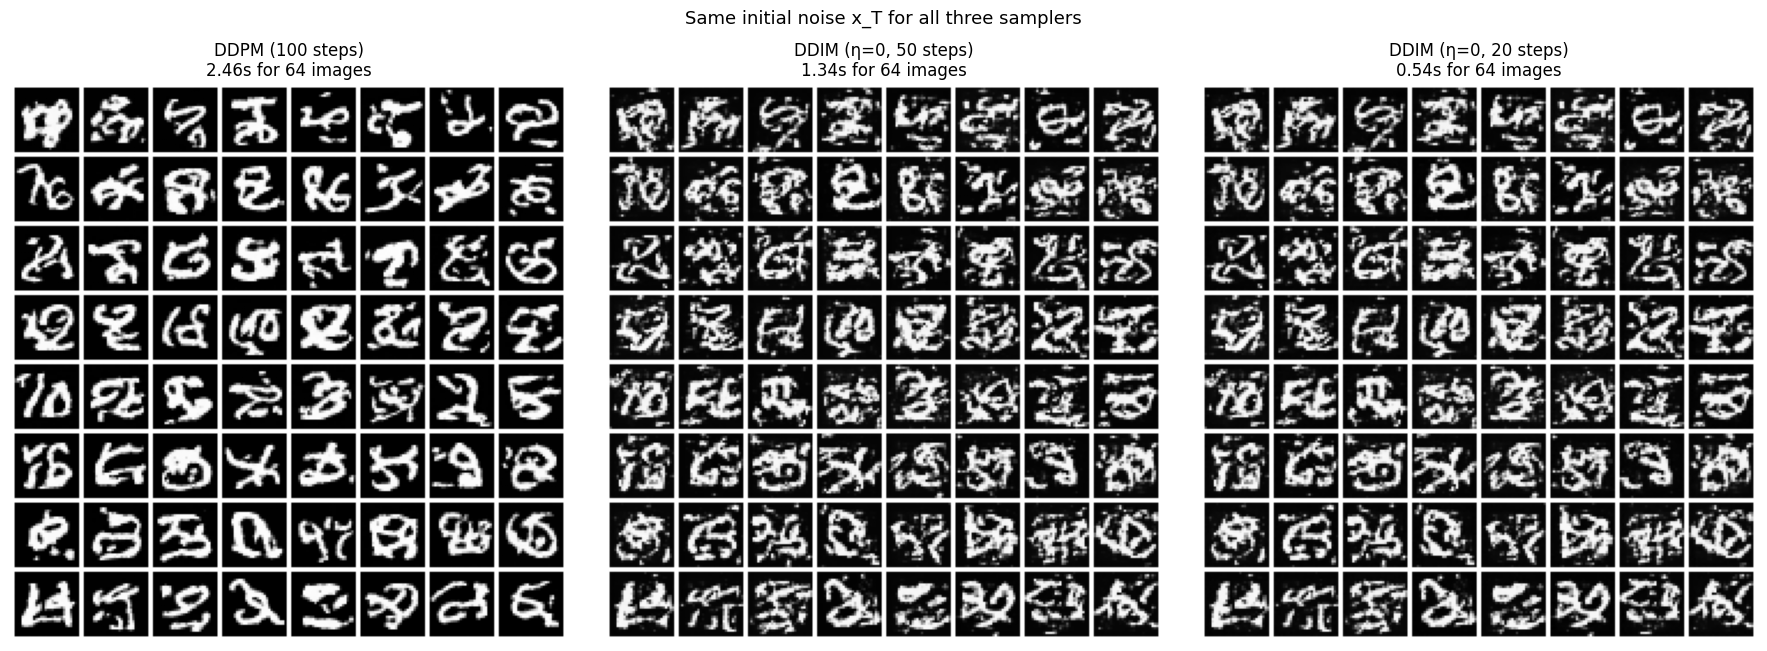

In [11]:
@torch.no_grad()
def ddim_sample(net, xT, n_steps, eta=0.0):
    seq = np.linspace(T_STEPS, 0, n_steps + 1).round().astype(int)  # e.g. 100, 95, ..., 5, 0
    x = xT
    for t, s in zip(seq[:-1], seq[1:]):
        tt = torch.full((x.size(0),), int(t), device=device)
        eps = net(x, tt)
        ab_t, ab_s = alpha_bar[t], alpha_bar[s]
        x0_hat = ((x - (1 - ab_t).sqrt() * eps) / ab_t.sqrt()).clamp(-1, 1)
        eps = (x - ab_t.sqrt() * x0_hat) / (1 - ab_t).sqrt()
        sigma = eta * ((1 - ab_s) / (1 - ab_t) * (1 - ab_t / ab_s)).sqrt()
        x = ab_s.sqrt() * x0_hat + (1 - ab_s - sigma**2).clamp(min=0).sqrt() * eps
        if eta > 0 and s > 0:
            x = x + sigma * torch.randn_like(x)
    return x


results = {"DDPM (100 steps)": (ddpm_imgs, ddpm_time)}
for S in [100, 50, 20]:
    t0 = time.time()
    imgs = ddim_sample(ema, xT, S)
    results[f"DDIM (η=0, {S} steps)"] = (imgs, time.time() - t0)
torch.manual_seed(SEED)
results["DDIM (η=1, 100 steps) ≈ DDPM"] = (ddim_sample(ema, xT, 100, eta=1.0), float("nan"))

fig, axes = plt.subplots(1, 3, figsize=(18, 6.6))
for ax, name in zip(axes, ["DDPM (100 steps)", "DDIM (η=0, 50 steps)", "DDIM (η=0, 20 steps)"]):
    imgs, secs = results[name]
    show(imgs, ax=ax, title=f"{name}\n{secs:.2f}s for {N_SAMPLES} images")
plt.suptitle("Same initial noise x_T for all three samplers", fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

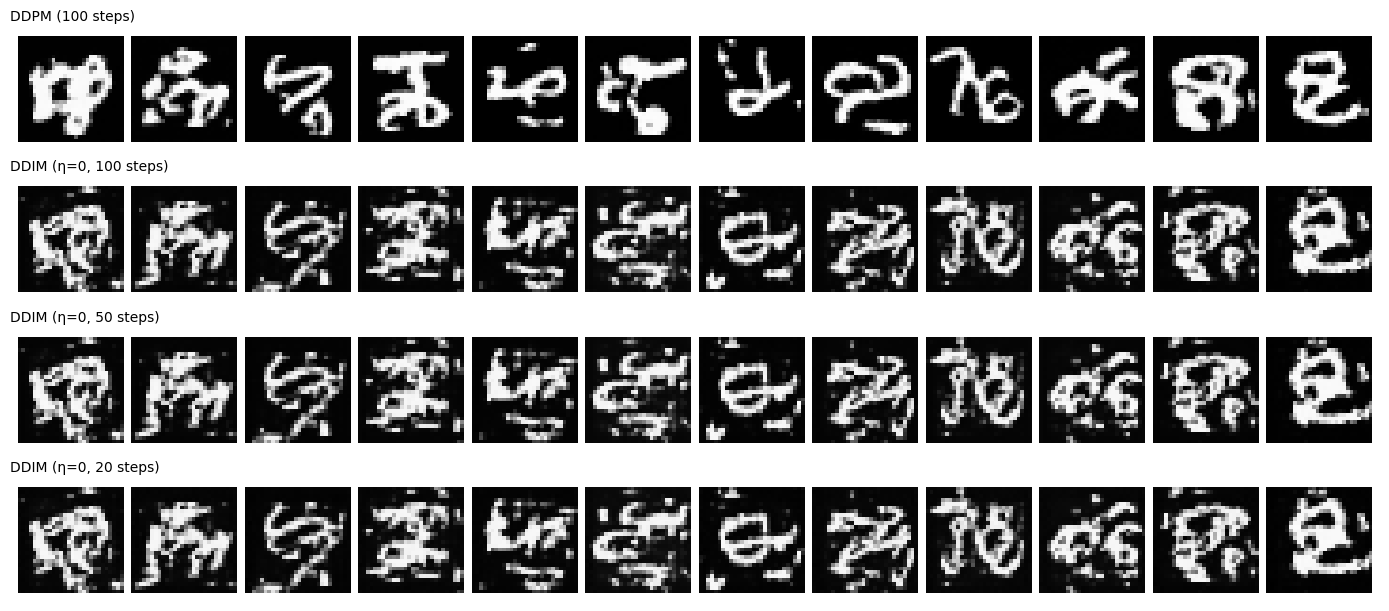

Mean per-pixel L2 distance between samples that start from the same x_T:
  DDIM-100 vs DDIM-50 : 0.006
  DDIM-100 vs DDIM-20 : 0.022
  DDIM-50  vs DDIM-20 : 0.016
  DDPM-100 vs DDIM-100: 0.563


In [12]:
# Side by side: the same 12 starting noises through each sampler (one column per sample)
names = ["DDPM (100 steps)", "DDIM (η=0, 100 steps)", "DDIM (η=0, 50 steps)", "DDIM (η=0, 20 steps)"]
fig, axes = plt.subplots(len(names), 1, figsize=(14, 1.45 * len(names) + 0.4))
for ax, name in zip(axes, names):
    show(results[name][0][:12], nrow=12, ax=ax)
    ax.set_title(name, fontsize=10, loc="left")
plt.tight_layout()
plt.show()

a, b, c = (results[f"DDIM (η=0, {S} steps)"][0] for S in [100, 50, 20])
d = results["DDPM (100 steps)"][0]
print("Mean per-pixel L2 distance between samples that start from the same x_T:")
print(f"  DDIM-100 vs DDIM-50 : {(a - b).pow(2).mean().sqrt().item():.3f}")
print(f"  DDIM-100 vs DDIM-20 : {(a - c).pow(2).mean().sqrt().item():.3f}")
print(f"  DDIM-50  vs DDIM-20 : {(b - c).pow(2).mean().sqrt().item():.3f}")
print(f"  DDPM-100 vs DDIM-100: {(d - a).pow(2).mean().sqrt().item():.3f}")

### Quantitative check with an MNIST classifier

Visual inspection alone is subjective, so a small CNN classifier is trained on real MNIST (2 epochs, ≈99% test
accuracy) and used as a judge, in the spirit of the Inception Score. For each sampler, 1000 images are generated and we report:

* **mean confidence:** the average max softmax probability. Higher means the samples look like clear digits.
* **class entropy:** the entropy of the predicted class histogram. The maximum is ln 10 ≈ 2.303, reached when all digits appear equally often.
* **mean pixel value and fraction of pixels that are near 0 or 1:** real MNIST is almost binary.

classifier test accuracy: 0.9865


sampler              net evals  time (s)  confidence  class ent.  mean px  near 0/1


Real MNIST (test)            -       nan       0.984       2.295    0.122     0.915
DDPM (100 steps)           100     39.19       0.839       1.818    0.225     0.847
DDIM (50 steps)             50     20.97       0.821       1.495    0.278     0.731
DDIM (20 steps)             20      8.36       0.819       1.502    0.278     0.728


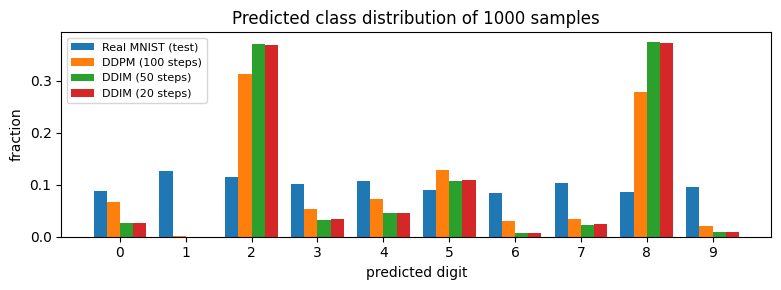

In [13]:
clf = nn.Sequential(
    nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Linear(128, 10),
).to(device)
copt = torch.optim.Adam(clf.parameters(), lr=1e-3)
for _ in range(2):
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        loss = F.cross_entropy(clf(x), y)
        copt.zero_grad()
        loss.backward()
        copt.step()
clf.eval()
test_loader = torch.utils.data.DataLoader(test, batch_size=1000)
with torch.no_grad():
    acc = np.mean([(clf(x.to(device)).argmax(1).cpu() == y).float().mean().item() for x, y in test_loader])
print(f"classifier test accuracy: {acc:.4f}")


def judge(imgs):
    with torch.no_grad():
        p = F.softmax(clf(imgs.clamp(-1, 1)), 1).cpu()
    hist = torch.bincount(p.argmax(1), minlength=10).float() / len(p)
    ent = -(hist[hist > 0] * hist[hist > 0].log()).sum().item()
    px = imgs.clamp(-1, 1) * 0.5 + 0.5
    binary = ((px < 0.1) | (px > 0.9)).float().mean().item()
    return p.max(1).values.mean().item(), ent, px.mean().item(), binary, hist


N_EVAL = 1000
g = torch.Generator(device="cpu").manual_seed(SEED + 1)
xT_eval = torch.randn(N_EVAL, 1, 28, 28, generator=g).to(device)
torch.manual_seed(SEED)
evals = {"Real MNIST (test)": (test_x[:N_EVAL], float("nan"))}
t0 = time.time(); evals["DDPM (100 steps)"] = (ddpm_sample(ema, xT_eval), time.time() - t0)
for S in [50, 20]:
    t0 = time.time(); evals[f"DDIM (50 steps)" if S == 50 else "DDIM (20 steps)"] = (ddim_sample(ema, xT_eval, S), time.time() - t0)

print(f"{'sampler':<20}{'net evals':>10}{'time (s)':>10}{'confidence':>12}{'class ent.':>12}{'mean px':>9}{'near 0/1':>10}")
nfe = {"Real MNIST (test)": "-", "DDPM (100 steps)": 100, "DDIM (50 steps)": 50, "DDIM (20 steps)": 20}
hists = {}
for name, (imgs, secs) in evals.items():
    conf, ent, mpx, binary, hist = judge(imgs)
    hists[name] = hist
    print(f"{name:<20}{nfe[name]:>10}{secs:>10.2f}{conf:>12.3f}{ent:>12.3f}{mpx:>9.3f}{binary:>10.3f}")

plt.figure(figsize=(8, 3))
w = 0.2
for i, (name, h) in enumerate(hists.items()):
    plt.bar(np.arange(10) + (i - 1.5) * w, h, width=w, label=name)
plt.xticks(range(10))
plt.xlabel("predicted digit")
plt.ylabel("fraction")
plt.title(f"Predicted class distribution of {N_EVAL} samples")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Effect of the short schedule: starting from x_T instead of pure noise

As shown in (a), with this schedule the model was trained on x_100 images that still contain 60% signal.
This extra experiment (not part of the required config) gives a sense of how much the train/test mismatch costs.
Test digits are noised to t = 100 with `q_sample`, which is exactly the distribution the model was trained on, and then
denoised with DDIM-20. The results should reconstruct a digit close to the original, which shows that the reverse process works
when the starting distribution is right.

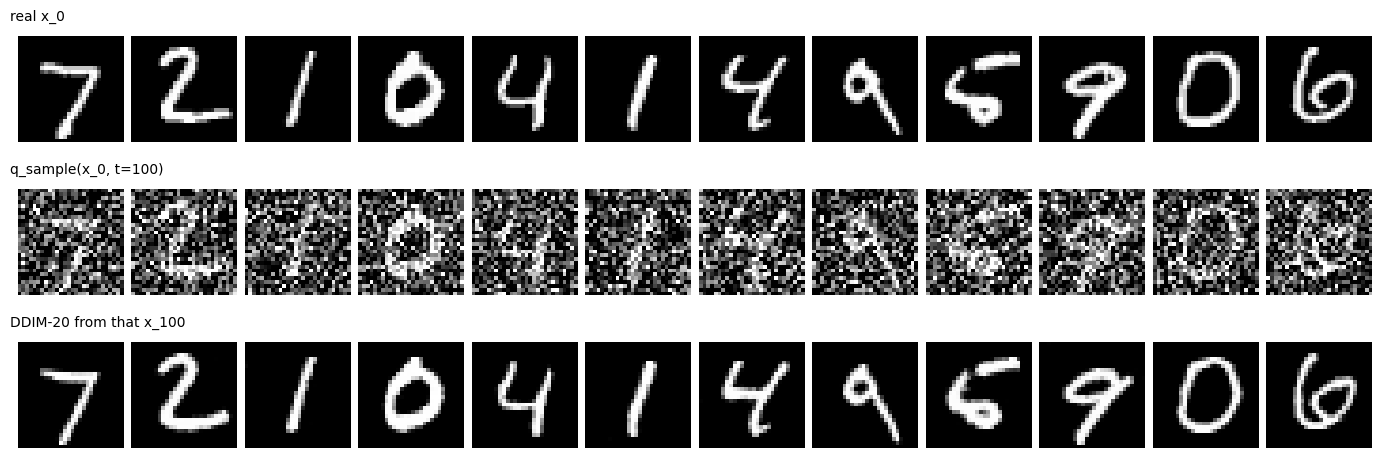

In [14]:
g = torch.Generator(device="cpu").manual_seed(SEED + 2)
x0_real = test_x[:12]
x100 = q_sample(x0_real, torch.full((12,), T_STEPS, device=device), torch.randn(x0_real.shape, generator=g).to(device))
recon = ddim_sample(ema, x100, 20)
fig, axes = plt.subplots(3, 1, figsize=(14, 4.8))
for ax, x, name in zip(axes, [x0_real, x100, recon], ["real x_0", "q_sample(x_0, t=100)", "DDIM-20 from that x_100"]):
    show(x, nrow=12, ax=ax)
    ax.set_title(name, fontsize=10, loc="left")
plt.tight_layout()
plt.show()

## Extension: the same experiment with a schedule that reaches pure noise

All results above use the required configuration. To separate the effect of the schedule from the effect of the
model and the samplers, a second, identical U-Net is trained with everything unchanged (T = 100, linear β, same
architecture, optimizer, 50 epochs, EMA) **except that β is scaled by 1000 / T = 10**, so it runs from 0.001 to 0.2.
This is the standard way to shorten the DDPM schedule (Nichol and Dhariwal, 2021). It gives the same endpoint as the
original T = 1000 schedule, ᾱ_T ≈ 4·10⁻⁵, so x_T really is N(0, I) and sampling starts from the distribution the model was
trained on.

`q_sample`, `ddpm_sample` and `ddim_sample` read the global `betas`, `alphas` and `alpha_bar`, so the schedule
globals are swapped here and every function is reused unchanged.

scaled schedule: alpha_bar_T = 2.04e-05  (required schedule: 0.364)


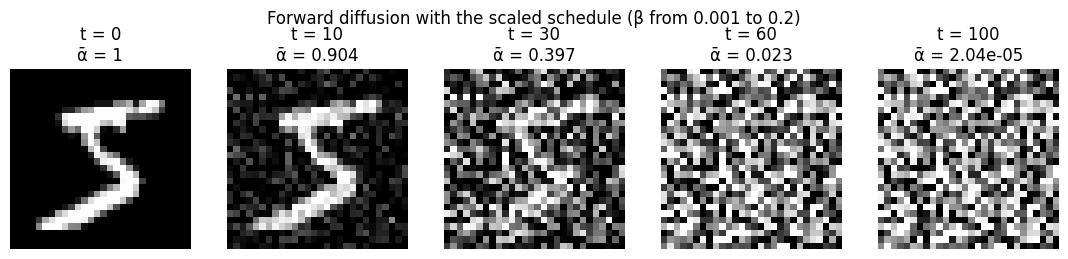

epoch   1  loss 0.0814  elapsed 63s


epoch   5  loss 0.0283  elapsed 321s


epoch  10  loss 0.0250  elapsed 663s


epoch  15  loss 0.0238  elapsed 1015s


epoch  20  loss 0.0231  elapsed 1371s


epoch  25  loss 0.0228  elapsed 1735s


epoch  30  loss 0.0222  elapsed 2103s


epoch  35  loss 0.0222  elapsed 2474s


epoch  40  loss 0.0219  elapsed 2847s


epoch  45  loss 0.0220  elapsed 3219s


epoch  50  loss 0.0217  elapsed 3593s


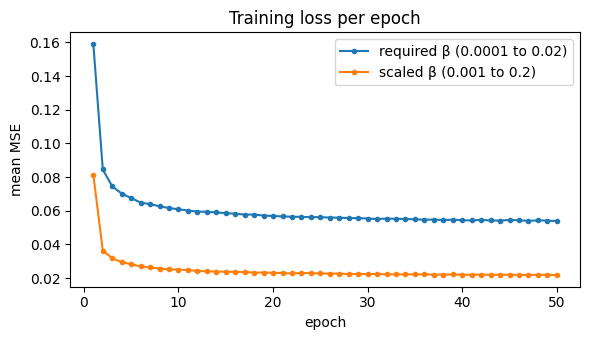

In [15]:
betas_req, alphas_req, alpha_bar_req = betas, alphas, alpha_bar  # keep the required schedule

betas = torch.cat([torch.zeros(1), torch.linspace(1e-3, 0.2, T_STEPS)]).to(device)
alphas = 1 - betas
alpha_bar = torch.cumprod(alphas, 0)
print(f"scaled schedule: alpha_bar_T = {alpha_bar[T_STEPS].item():.2e}  (required schedule: {alpha_bar_req[T_STEPS].item():.3f})")

fig, axes = plt.subplots(1, len(ts), figsize=(2.2 * len(ts), 2.6))
for ax, t in zip(axes, ts):
    xt = q_sample(x0, torch.tensor([t], device=device), eps_vis)
    ax.imshow(xt[0, 0].cpu() * 0.5 + 0.5, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"t = {t}\nᾱ = {alpha_bar[t].item():.3g}")
    ax.axis("off")
plt.suptitle("Forward diffusion with the scaled schedule (β from 0.001 to 0.2)")
plt.tight_layout()
plt.show()

torch.manual_seed(SEED)
model_s = UNet().to(device)
ema_s, step_losses_s, epoch_losses_s = train_ddpm(model_s, EPOCHS)
torch.save(ema_s.state_dict(), "ddpm_mnist_ema_scaled_beta.pt")

plt.figure(figsize=(6, 3.5))
plt.plot(range(1, EPOCHS + 1), epoch_losses, marker="o", ms=3, label="required β (0.0001 to 0.02)")
plt.plot(range(1, EPOCHS + 1), epoch_losses_s, marker="o", ms=3, label="scaled β (0.001 to 0.2)")
plt.xlabel("epoch")
plt.ylabel("mean MSE")
plt.title("Training loss per epoch")
plt.legend()
plt.tight_layout()
plt.show()

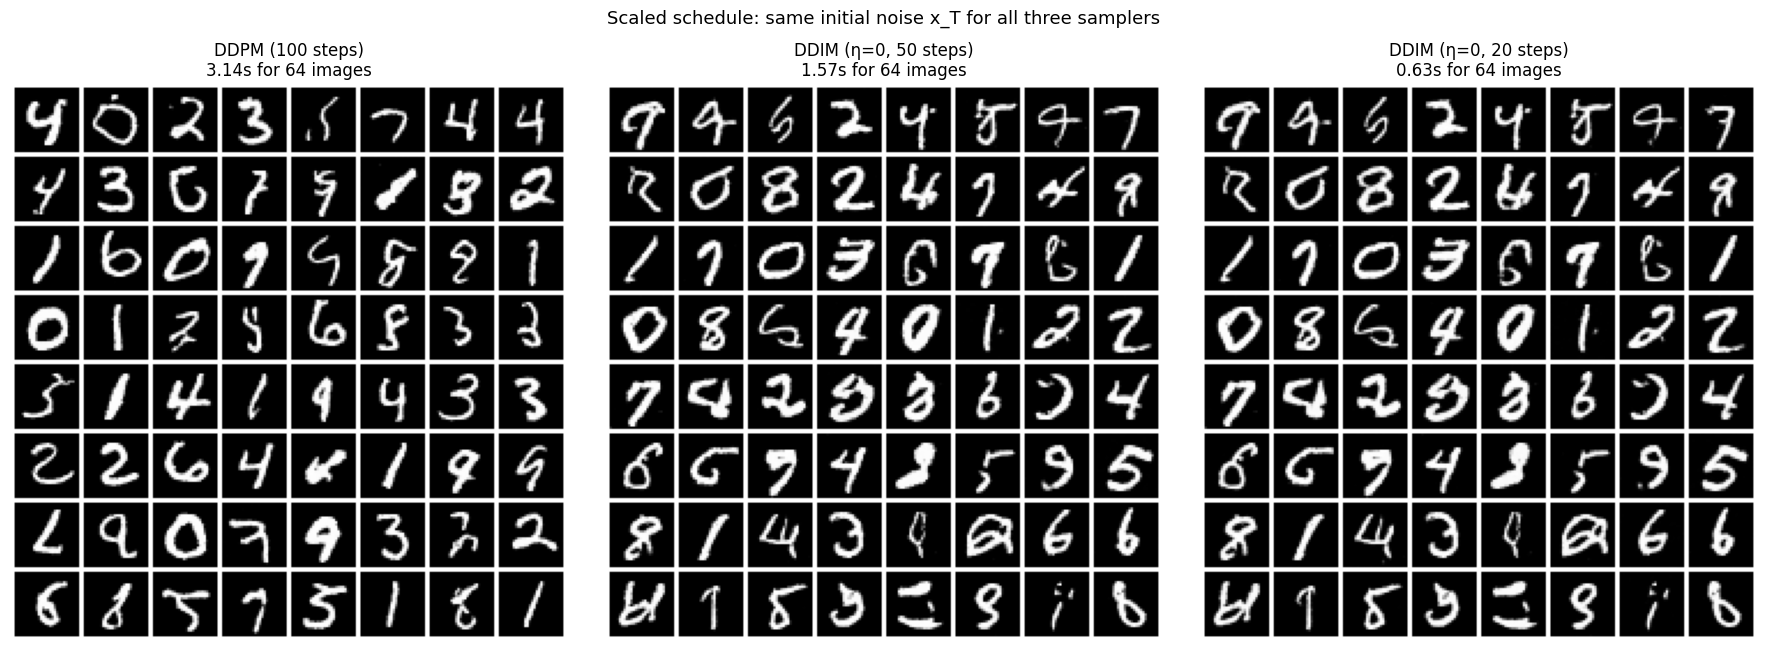

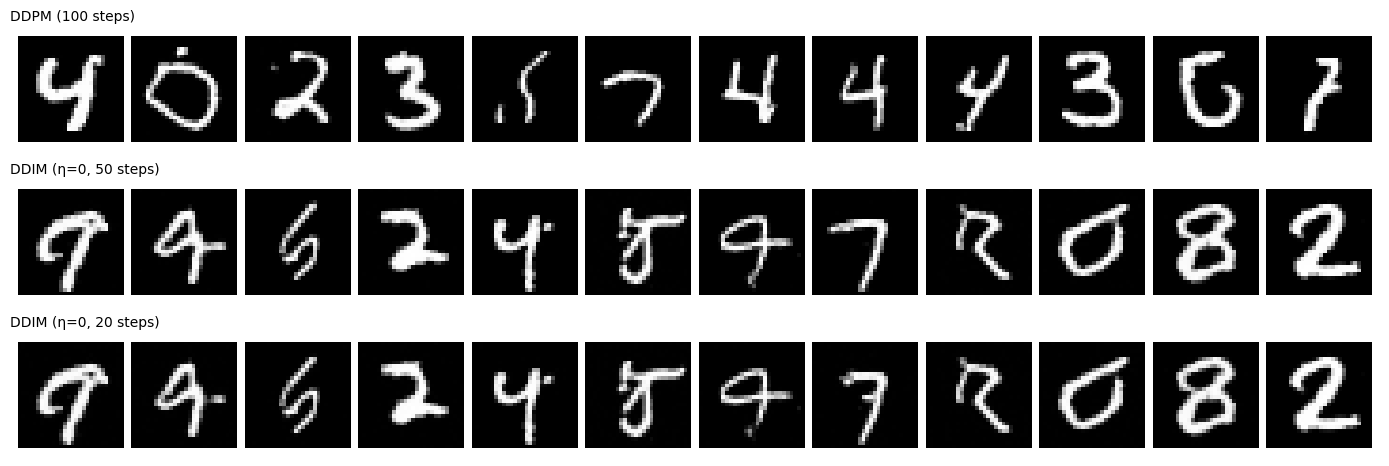

Mean per-pixel L2 distance between samples that start from the same x_T (scaled schedule):
  DDPM-100 vs DDIM-50: 0.707
  DDIM-50  vs DDIM-20: 0.054


In [16]:
torch.manual_seed(SEED)
results_s = {}
t0 = time.time(); results_s["DDPM (100 steps)"] = (ddpm_sample(ema_s, xT), time.time() - t0)
for S in [50, 20]:
    t0 = time.time(); results_s[f"DDIM (η=0, {S} steps)"] = (ddim_sample(ema_s, xT, S), time.time() - t0)

fig, axes = plt.subplots(1, 3, figsize=(18, 6.6))
for ax, (name, (imgs, secs)) in zip(axes, results_s.items()):
    show(imgs, ax=ax, title=f"{name}\n{secs:.2f}s for {N_SAMPLES} images")
plt.suptitle("Scaled schedule: same initial noise x_T for all three samplers", fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

fig, axes = plt.subplots(3, 1, figsize=(14, 4.8))
for ax, (name, (imgs, _)) in zip(axes, results_s.items()):
    show(imgs[:12], nrow=12, ax=ax)
    ax.set_title(name, fontsize=10, loc="left")
plt.tight_layout()
plt.show()

a, b, c = (results_s[n][0] for n in results_s)
print("Mean per-pixel L2 distance between samples that start from the same x_T (scaled schedule):")
print(f"  DDPM-100 vs DDIM-50: {(a - b).pow(2).mean().sqrt().item():.3f}")
print(f"  DDIM-50  vs DDIM-20: {(b - c).pow(2).mean().sqrt().item():.3f}")

Scaled schedule, 1000 samples per sampler
sampler              net evals  time (s)  confidence  class ent.  mean px  near 0/1


Real MNIST (test)            -       nan       0.984       2.295    0.122     0.915
DDPM (100 steps)           100     46.71       0.930       2.290    0.128     0.916
DDIM (50 steps)             50     24.74       0.906       2.291    0.132     0.909
DDIM (20 steps)             20      9.90       0.900       2.289    0.130     0.905


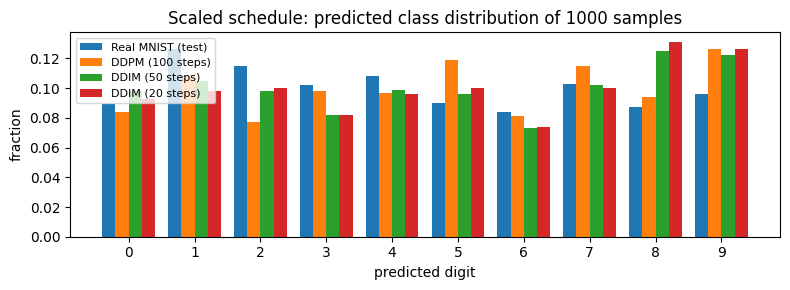

In [17]:
torch.manual_seed(SEED)
evals_s = {"Real MNIST (test)": (test_x[:N_EVAL], float("nan"))}
t0 = time.time(); evals_s["DDPM (100 steps)"] = (ddpm_sample(ema_s, xT_eval), time.time() - t0)
t0 = time.time(); evals_s["DDIM (50 steps)"] = (ddim_sample(ema_s, xT_eval, 50), time.time() - t0)
t0 = time.time(); evals_s["DDIM (20 steps)"] = (ddim_sample(ema_s, xT_eval, 20), time.time() - t0)

print("Scaled schedule, 1000 samples per sampler")
print(f"{'sampler':<20}{'net evals':>10}{'time (s)':>10}{'confidence':>12}{'class ent.':>12}{'mean px':>9}{'near 0/1':>10}")
hists_s = {}
for name, (imgs, secs) in evals_s.items():
    conf, ent, mpx, binary, hist = judge(imgs)
    hists_s[name] = hist
    print(f"{name:<20}{nfe[name]:>10}{secs:>10.2f}{conf:>12.3f}{ent:>12.3f}{mpx:>9.3f}{binary:>10.3f}")

plt.figure(figsize=(8, 3))
for i, (name, h) in enumerate(hists_s.items()):
    plt.bar(np.arange(10) + (i - 1.5) * w, h, width=w, label=name)
plt.xticks(range(10))
plt.xlabel("predicted digit")
plt.ylabel("fraction")
plt.title(f"Scaled schedule: predicted class distribution of {N_EVAL} samples")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Discussion: DDPM vs DDIM

All numbers below come from the outputs above (1000 samples per sampler, judged by a classifier with 98.7% test accuracy).

**Required schedule (T = 100, β from 0.0001 to 0.02)**

| sampler | net evals | time (s) | confidence | class entropy | near 0/1 pixels |
|---|---|---|---|---|---|
| Real MNIST | - | - | 0.984 | 2.295 | 0.915 |
| DDPM | 100 | 39.2 | 0.839 | 1.818 | 0.847 |
| DDIM | 50 | 21.0 | 0.821 | 1.495 | 0.731 |
| DDIM | 20 | 8.4 | 0.819 | 1.502 | 0.728 |

**Scaled schedule (extension, β from 0.001 to 0.2)**

| sampler | net evals | time (s) | confidence | class entropy | near 0/1 pixels |
|---|---|---|---|---|---|
| DDPM | 100 | 46.7 | 0.930 | 2.290 | 0.916 |
| DDIM | 50 | 24.7 | 0.906 | 2.291 | 0.909 |
| DDIM | 20 | 9.9 | 0.900 | 2.289 | 0.905 |

**Same model, different samplers.** DDPM and DDIM use the same trained ε_θ. DDIM needs no retraining, because the
training loss only depends on the marginals q(x_t | x_0), and DDIM keeps those marginals and only changes the
reverse process.

**Speed.** Sampling time is set by the number of network evaluations. DDPM has to visit all 100 timesteps, because each
step is a small Gaussian move matched to one β_t. DDIM can skip timesteps. DDIM-50 was about 1.9× faster and DDIM-20
about 4.7× faster than DDPM in both experiments. Since T is only 100, the absolute savings are small here. With the
usual T = 1000, going down to 20 to 50 steps is a 20 to 50× speedup.

**Stochastic vs deterministic.** DDPM adds fresh noise at every step, so the final digit is only loosely tied to
x_T. DDIM with η = 0 adds no noise, so x_T fully determines the output. In the side-by-side figures, DDIM-100, DDIM-50
and DDIM-20 started from the same x_T give the same digit in the same style, while DDPM gives a different digit. The
pixel L2 distance between DDIM-50 and DDIM-20 is only 0.016 (required) and 0.054 (scaled), compared with 0.56 and 0.71
between DDPM and DDIM. This means DDIM's x_T works like a latent code that stays consistent across step counts.

**Quality.** With the scaled schedule, all three samplers produce clear and varied digits. Their class entropy
(≈ 2.29) and fraction of near 0/1 pixels (0.905 to 0.916) are almost identical to real MNIST, so no sampler collapses
to a few digits. DDPM is slightly better on every measure (confidence 0.930 vs 0.906 and 0.900). DDIM loses very little
going from 50 to 20 steps. Its strokes are a little smoother, and a few samples are more ambiguous. This is because
each DDIM jump relies on one prediction of x̂_0, while DDPM's random steps can correct earlier mistakes. For a 4.7×
speedup the quality loss is small, which is the main practical argument for DDIM.

**Why the required schedule gives scribbles.** With T = 100 and β_max = 0.02, ᾱ_100 ≈ 0.36, so during training x_100
still holds 60% of the image (see part a). Sampling starts from pure N(0, I), which the model never saw at t = 100. It
treats part of that noise as image content, so the outputs are digit-like strokes, mostly classified as 2 or 8 (class
entropy 1.5 to 1.8). The model itself is fine: when it starts from a correctly noised x_100 it reconstructs the digit
(the "starting from x_T" experiment), and with the scaled schedule the same network and training give good samples.
The problem is only the mismatch between the training and sampling distributions at t = T. Under this mismatch DDPM
does better than DDIM (near 0/1 pixels 0.847 vs 0.73, entropy 1.82 vs 1.50). Its fresh noise and repeated x̂_0
clipping gradually replace the leftover input noise. Deterministic DDIM carries the leftover noise through to the
end, which shows up as speckle.

**Training loss.** The required schedule ends at loss 0.054 and the scaled one at 0.022. These values cannot be compared
directly. With the scaled schedule most timesteps are very noisy, and predicting ε is easy when x_t is mostly ε.
In both runs the loss drops quickly in the first few epochs and then flattens out, and the error is largest at small
t, where only a tiny amount of noise has to be separated from the image.

**Summary.** DDPM gives the best samples but needs every step. DDIM gives almost the same quality with 2.5 to 5× fewer
steps, and it is deterministic, so x_T can be used as a latent code. Both depend on a noise schedule that actually
reaches pure noise at t = T. The required T = 100 schedule does not, and that, not the sampler, limits sample quality.